# Sampling Diffusion Models on MNIST

Notebook 10 trained one denoising diffusion probabilistic model (DDPM). This notebook keeps that **same trained noise predictor and same cosine noise schedule** fixed, then changes only the numerical procedure used to travel from noise to data.

### Learning goals

1. Revisit ancestral **DDPM sampling** as a $T$-step stochastic Markov chain.
2. Derive **DDIM**, which can skip training steps and continuously controls reverse-process randomness with $\eta$.
3. Interpret diffusion sampling through the reverse-time SDE and probability-flow ODE.
4. Implement a compact **DPM-Solver++(2M)** sampler as an example of a modern diffusion-specific numerical solver.
5. Compare neural-function evaluations (NFE), wall-clock speed, sample quality, class coverage, and stochasticity under controlled initial noise.

> The denoiser is not retrained. Run notebook 10 first if `notebooks/checkpoints/ddpm_mnist.pt` is missing. Keeping the model fixed is essential. Differences below then come from the sampler rather than training.


## Before you begin

**Prerequisites.** Complete notebook 10 or know DDPM noise prediction, the cosine schedule, and the distinction between a model and a numerical sampler. Notebook 10 supplies the fixed checkpoint. Notebook 05 provides the ring-level diffusion intuition.

> **Notation and orientation**
> - NFE counts denoiser evaluations. $\eta$ controls DDIM stochasticity. $\lambda=\log(\alpha/\sigma)$ is log-SNR.
> - **Unchanged from training:** the learned $\epsilon_\theta$, data representation, and noise schedule.
> - **Changed at sampling time:** state spacing, update rule, order, stochasticity, latency, and discretization error. Image scale makes each NFE expensive enough to measure.

## 1. Setup

The default experiment generates 100 images per method. On a CPU, reduce `N_SAMPLES` or omit some entries from `SAMPLER_SPECS`. The ancestral baseline necessarily evaluates the U-Net $T$ times.

Paths are resolved both when Jupyter starts in the repository root and when it starts inside `notebooks/`.

In [1]:
import gzip
import struct
import time
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"
T = 300
BASE_CHANNELS = 32
N_SAMPLES = 100
EVALUATOR_EPOCHS = 3


NOTEBOOK_DIR = Path("notebooks") if Path("notebooks").is_dir() else Path(".")


CHECKPOINT = NOTEBOOK_DIR / "checkpoints/ddpm_mnist.pt"
if not CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Missing {CHECKPOINT}. Run 10_diffusion_mnist.ipynb to train the denoiser first."
    )

PLOT_THEME = "light"  # Change to "dark" for the dark plot palette.
if PLOT_THEME not in {"light", "dark"}:
    raise ValueError("PLOT_THEME must be 'light' or 'dark'.")

# Start from Matplotlib defaults so light mode keeps the standard coloring.
plt.style.use("default")
if PLOT_THEME == "dark":
    plt.style.use("dark_background")
    plt.rcParams.update(
        {
            "figure.facecolor": "#0a0f18",
            "figure.edgecolor": "#0a0f18",
            "axes.facecolor": "#111926",
            "axes.edgecolor": "#e8eff9",
            "axes.labelcolor": "#e8eff9",
            "axes.titlecolor": "#e8eff9",
            "text.color": "#e8eff9",
            "xtick.color": "#e8eff9",
            "ytick.color": "#e8eff9",
            "grid.color": "#2b3340",
            "savefig.facecolor": "#0a0f18",
            "savefig.edgecolor": "#0a0f18",
        }
    )

PLOT_REFERENCE_COLOR = "black" if PLOT_THEME == "light" else "#6cd2e8"
PLOT_GENERATED_COLOR = "tab:orange" if PLOT_THEME == "light" else "#f09a4b"
PLOT_GUIDE_COLOR = "black" if PLOT_THEME == "light" else "#e8eff9"

plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": False, "font.size": 11})
print(f"PyTorch {torch.__version__} | device: {DEVICE} | checkpoint: {CHECKPOINT}")


PyTorch 2.12.0+cu130 | device: cuda | checkpoint: checkpoints/ddpm_mnist.pt


## 2. Reconstruct the training noise schedule

Notebook 10 used a variance-preserving cosine schedule. We write

$$x_t=\alpha_t^{\mathrm{(c)}}x_0+\sigma_t\epsilon,
\qquad
\alpha_t^{\mathrm{(c)}}=\sqrt{\bar\alpha_t},
\qquad
\sigma_t=\sqrt{1-\bar\alpha_t}.$$

The superscript distinguishes the cumulative signal coefficient $\alpha_t^{\mathrm{(c)}}$ from the one-step DDPM coefficient $\alpha_t=1-\beta_t$. The code uses zero-based array indices, while sampler state `s` uses the mathematical states $x_s$, with $s\in\{0,\ldots,T\}$.

A trained denoiser assigns meaning to each time index through this schedule, so changing the schedule without retraining would not be a fair sampler comparison.


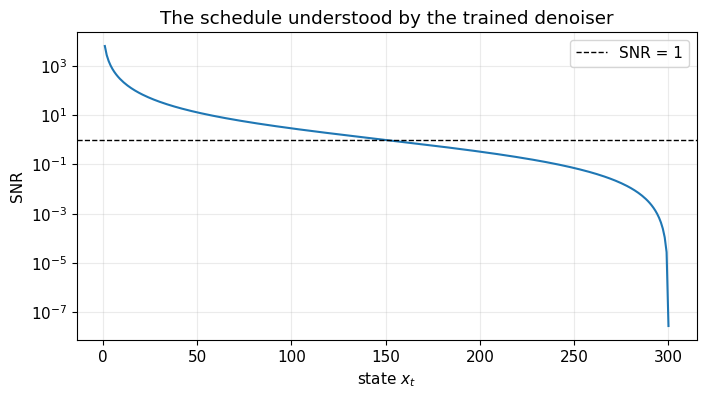

In [2]:
def cosine_beta_schedule(n_steps, offset=0.008):
    """Cosine schedule from Nichol & Dhariwal (2021)."""
    steps = torch.arange(n_steps + 1, dtype=torch.float64)
    f = torch.cos(((steps / n_steps + offset) / (1 + offset)) * torch.pi / 2).square()
    alpha_bar = f / f[0]
    betas = 1 - alpha_bar[1:] / alpha_bar[:-1]
    return betas.clamp(1e-5, 0.999).float()


betas = cosine_beta_schedule(T).to(DEVICE)
alphas = 1 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_previous = torch.cat([torch.ones(1, device=DEVICE), alpha_bars[:-1]])
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1 - alpha_bars)

posterior_variance = betas * (1 - alpha_bars_previous) / (1 - alpha_bars)
posterior_mean_coefficient_x0 = (
    betas * torch.sqrt(alpha_bars_previous) / (1 - alpha_bars)
)
posterior_mean_coefficient_xt = (
    torch.sqrt(alphas) * (1 - alpha_bars_previous) / (1 - alpha_bars)
)


def alpha_bar_at_state(state):
    """Return cumulative signal power for x_state; x_0 has power one."""
    if state == 0:
        return torch.ones((), device=DEVICE)
    return alpha_bars[state - 1]


fig, ax = plt.subplots(figsize=(8, 4))
steps = torch.arange(1, T + 1)
ax.semilogy(steps.cpu(), (alpha_bars / (1 - alpha_bars)).cpu())
ax.axhline(1, color=PLOT_GUIDE_COLOR, linestyle="--", linewidth=1, label="SNR = 1")
ax.set(xlabel="state $x_t$", ylabel="SNR", title="The schedule understood by the trained denoiser")
ax.grid(alpha=0.25, which="both")
ax.legend()
plt.show()


## 3. Restore exactly the U-Net from notebook 10

The network predicts the noise $\epsilon_\theta(x_t,t)$. The exponential-moving-average weights are used for every sampler. Architecture and checkpoint loading are repeated here so this notebook can run independently after notebook 10 has produced the checkpoint.


In [3]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        assert dim % 2 == 0
        frequencies = torch.exp(
            -np.log(10_000) * torch.arange(dim // 2) / (dim // 2 - 1)
        )
        self.register_buffer("frequencies", frequencies)

    def forward(self, t):
        angles = t.float().unsqueeze(1) * self.frequencies.unsqueeze(0)
        return torch.cat([angles.sin(), angles.cos()], dim=1)


class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.time_projection = nn.Linear(time_dim, out_channels)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, 1)
        )

    def forward(self, x, time_features):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_projection(time_features)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class SmallUNet(nn.Module):
    def __init__(self, base=32, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(base * 2),
            nn.Linear(base * 2, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.input = nn.Conv2d(1, base, 3, padding=1)
        self.down1 = ResBlock(base, base, time_dim)
        self.downsample1 = nn.Conv2d(base, base * 2, 4, 2, 1)
        self.down2 = ResBlock(base * 2, base * 2, time_dim)
        self.downsample2 = nn.Conv2d(base * 2, base * 4, 4, 2, 1)
        self.middle1 = ResBlock(base * 4, base * 4, time_dim)
        self.middle2 = ResBlock(base * 4, base * 4, time_dim)
        self.upsample2 = nn.ConvTranspose2d(base * 4, base * 2, 4, 2, 1)
        self.up2 = ResBlock(base * 4, base * 2, time_dim)
        self.upsample1 = nn.ConvTranspose2d(base * 2, base, 4, 2, 1)
        self.up1 = ResBlock(base * 2, base, time_dim)
        self.output = nn.Sequential(
            nn.GroupNorm(8, base), nn.SiLU(), nn.Conv2d(base, 1, 3, padding=1)
        )

    def forward(self, x, t):
        time_features = self.time_mlp(t)
        x = self.input(x)
        skip1 = self.down1(x, time_features)
        skip2 = self.down2(self.downsample1(skip1), time_features)
        h = self.downsample2(skip2)
        h = self.middle1(h, time_features)
        h = self.middle2(h, time_features)
        h = self.upsample2(h)
        h = self.up2(torch.cat([h, skip2], dim=1), time_features)
        h = self.upsample1(h)
        h = self.up1(torch.cat([h, skip1], dim=1), time_features)
        return self.output(h)


model = SmallUNet(BASE_CHANNELS).to(DEVICE)
try:
    checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
except TypeError:  # Compatibility with older PyTorch releases.
    checkpoint = torch.load(CHECKPOINT, map_location=DEVICE)
model.load_state_dict(checkpoint["ema_model"])
model.eval().requires_grad_(False)
print(
    f"Loaded EMA weights from epoch {checkpoint.get('epoch', '?')} | "
    f"parameters: {sum(parameter.numel() for parameter in model.parameters()):,}"
)


Loaded EMA weights from epoch 30 | parameters: 1,244,705


## 4. Shared utilities and a controlled starting point

Every benchmark method receives the **same batch of initial Gaussian noise**. This removes a large source of visual variance when comparing deterministic samplers. NFE means the number of U-Net calls. For these implementations it equals the number of requested reverse steps.

The model's noise prediction also implies a clean-image prediction:

$$\hat x_0=\frac{x_s-\sqrt{1-\bar\alpha_s}\,\epsilon_\theta(x_s,s)}
{\sqrt{\bar\alpha_s}}.$$

As in notebook 10, $\hat x_0$ is clipped to the data range for stability.


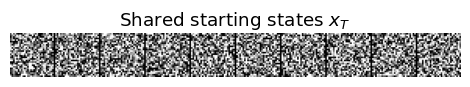

In [4]:
def make_generator(seed):
    device_name = "cuda" if DEVICE.type == "cuda" else "cpu"
    return torch.Generator(device=device_name).manual_seed(seed)


def randn_like(x, generator):
    return torch.randn(x.shape, device=x.device, dtype=x.dtype, generator=generator)


def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def timed(function):
    synchronize()
    start = time.perf_counter()
    value = function()
    synchronize()
    return value, time.perf_counter() - start


def make_state_grid(n_steps):
    """n_steps transitions from x_T to x_0, rounded onto training states."""
    if not 1 <= n_steps <= T:
        raise ValueError(f"n_steps must be between 1 and {T}")
    states = np.rint(np.linspace(T, 0, n_steps + 1)).astype(int).tolist()
    if any(left <= right for left, right in zip(states, states[1:])):
        raise ValueError("Rounded state grid is not strictly decreasing")
    return states


@torch.no_grad()
def predict_epsilon_and_x0(model, x_s, state):
    """Evaluate at x_state and convert epsilon prediction to x_0 prediction."""
    if not 1 <= state <= T:
        raise ValueError("The denoiser is evaluated only at noisy states 1,...,T")
    index = state - 1
    t = torch.full((len(x_s),), index, device=DEVICE, dtype=torch.long)
    predicted_epsilon = model(x_s, t)
    predicted_x0 = (
        x_s - sqrt_one_minus_alpha_bars[index] * predicted_epsilon
    ) / sqrt_alpha_bars[index]
    return predicted_epsilon, predicted_x0.clamp(-1, 1)


def show_image_grid(images, nrow=10, title=None, value_range=(-1, 1)):
    images = images.detach().cpu()
    if images.ndim == 4:
        images = images[:, 0]
    ncol = int(np.ceil(len(images) / nrow))
    canvas = torch.full(
        (ncol * 28 + ncol - 1, nrow * 28 + nrow - 1),
        fill_value=float(value_range[0]),
        dtype=images.dtype,
    )
    for index, image in enumerate(images):
        row, column = divmod(index, nrow)
        canvas[row * 29 : row * 29 + 28, column * 29 : column * 29 + 28] = image
    fig, ax = plt.subplots(figsize=(nrow, ncol))
    ax.imshow(canvas, cmap="gray", vmin=value_range[0], vmax=value_range[1])
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


initial_noise = torch.randn(
    N_SAMPLES, 1, 28, 28, device=DEVICE, generator=make_generator(SEED)
)
show_image_grid(initial_noise[:10], nrow=10, title="Shared starting states $x_T$")


## 5. Baseline: ancestral DDPM sampling

For every adjacent pair of states, the learned reverse transition is

$$p_\theta(x_{t-1}\mid x_t)=
\mathcal N\!\left(\tilde\mu_\theta(x_t,t),\tilde\beta_t I\right).$$

It follows the exact $T$-state training discretization and injects fresh Gaussian noise at every transition except the last. This is robust and genuinely stochastic, but it costs **$T$ sequential NFE** per batch. Neural evaluations cannot be parallelized across time because each state depends on its predecessor.


In [5]:
@torch.no_grad()
def sample_ddpm(model, initial_noise, generator=None):
    """Full adjacent-step ancestral chain from notebook 10."""
    if generator is None:
        generator = make_generator(SEED)
    x = initial_noise.clone()
    for state in range(T, 0, -1):
        index = state - 1
        _, predicted_x0 = predict_epsilon_and_x0(model, x, state)
        mean = (
            posterior_mean_coefficient_x0[index] * predicted_x0
            + posterior_mean_coefficient_xt[index] * x
        )
        if state > 1:
            x = mean + torch.sqrt(posterior_variance[index]) * randn_like(x, generator)
        else:
            x = mean
    return x


## 6. DDIM: skip states and choose the randomness

DDIM uses the same model and can jump directly from state $s$ to any earlier state $r<s$. Let $a_s=\bar\alpha_s$ and let $a_0=1$. One generalized update is

$$x_r=\sqrt{a_r}\,\hat x_0
+\sqrt{1-a_r-\sigma_{s\to r}^2}\,\epsilon_\theta(x_s,s)
+\sigma_{s\to r}z,$$

$$\sigma_{s\to r}=\eta
\sqrt{\frac{1-a_r}{1-a_s}\left(1-\frac{a_s}{a_r}\right)}.$$

- $\eta=0$: deterministic DDIM. Once $x_T$ is fixed, the entire output is fixed.
- $0<\eta\leq 1$: increasingly stochastic paths.
- Adjacent steps with $\eta=1$ recover the DDPM posterior variance, but strided $\eta=1$ is **not** the original adjacent DDPM chain.

The advantage is immediate: a 20-step grid needs 20 rather than 300 network calls. The cost is larger discretization error because the denoiser is queried at fewer noise levels.


In [6]:
@torch.no_grad()
def sample_ddim(model, initial_noise, n_steps=50, eta=0.0, generator=None):
    """Generalized DDIM transitions on a rounded subset of training states."""
    if not 0 <= eta <= 1:
        raise ValueError("eta must lie in [0, 1]")
    if generator is None:
        generator = make_generator(SEED)

    x = initial_noise.clone()
    states = make_state_grid(n_steps)
    for state, next_state in zip(states[:-1], states[1:]):
        predicted_epsilon, predicted_x0 = predict_epsilon_and_x0(model, x, state)
        a_s = alpha_bar_at_state(state)
        a_r = alpha_bar_at_state(next_state)
        sigma_squared = eta**2 * (1 - a_r) / (1 - a_s) * (1 - a_s / a_r)
        sigma_squared = sigma_squared.clamp(min=0)
        direction_squared = (1 - a_r - sigma_squared).clamp(min=0)
        noise = randn_like(x, generator) if eta > 0 and next_state > 0 else 0.0
        x = (
            torch.sqrt(a_r) * predicted_x0
            + torch.sqrt(direction_squared) * predicted_epsilon
            + torch.sqrt(sigma_squared) * noise
        )
    return x


## 7. Continuous time: SDE paths and a probability-flow ODE

A variance-preserving diffusion can be idealized by the forward stochastic differential equation

$$d x=-\tfrac12\beta(t)x\,dt+\sqrt{\beta(t)}\,dW_t.$$

Its reverse-time SDE contains the score $\nabla_x\log p_t(x)$ and remains stochastic. For an epsilon-predicting model,

$$s_\theta(x,t)\approx\nabla_x\log p_t(x)
=-\frac{\epsilon_\theta(x,t)}{\sigma(t)}.$$

The same time marginals also satisfy the deterministic **probability-flow ODE**

$$d x=\left[-\tfrac12\beta(t)x-\tfrac12\beta(t)s_\theta(x,t)\right]dt.$$

This viewpoint reframes generation as numerical integration. DDIM is closely related to a first-order discretization of that deterministic flow. Generic Runge-Kutta methods can be used, but every score evaluation is an expensive U-Net call and the dynamics become stiff near low noise. Modern diffusion solvers therefore integrate in a better coordinate and exploit the known linear part analytically.

### Log-SNR and DPM-Solver++(2M)

Define

$$\lambda_s=\log\frac{\alpha_s^{\mathrm{(c)}}}{\sigma_s}.$$

During generation, $\lambda$ increases from noise toward data. The DPM-Solver++ integrates the clean-data prediction and exactly handles the analytically known linear coefficients. The compact implementation below uses the **second-order multistep midpoint rule** after one first-order startup step. It needs only one new model evaluation per state. `2M` means second order, multistep—not two evaluations per step.

This is an educational fixed-grid implementation, not a feature-complete scheduler library. Production versions add specialized time grids, dynamic thresholding, adaptive order, and careful low-order final steps.


In [7]:
def alpha_sigma_lambda(state):
    """Continuous-time coefficients sampled at one discrete training state."""
    a_bar = alpha_bar_at_state(state)
    alpha = torch.sqrt(a_bar)
    sigma = torch.sqrt(1 - a_bar)
    log_snr_half = torch.log(alpha) - torch.log(sigma)
    return alpha, sigma, log_snr_half


@torch.no_grad()
def sample_dpmpp_2m(model, initial_noise, n_steps=20):
    """DPM-Solver++(2M), data-prediction form with midpoint coefficients."""
    x = initial_noise.clone()
    states = make_state_grid(n_steps)
    previous_x0 = None
    previous_lambda = None

    for state, next_state in zip(states[:-1], states[1:]):
        _, predicted_x0 = predict_epsilon_and_x0(model, x, state)
        alpha_s, sigma_s, lambda_s = alpha_sigma_lambda(state)

        # At the clean endpoint sigma=0 and lambda=+infinity. A first-order
        # low-noise final step reduces exactly to the current x_0 prediction.
        if next_state == 0:
            x = predicted_x0
        else:
            alpha_t, sigma_t, lambda_t = alpha_sigma_lambda(next_state)
            h = lambda_t - lambda_s
            exponential_remainder = torch.expm1(-h)

            if previous_x0 is None:
                # DPM-Solver++ first-order startup.
                x = (
                    (sigma_t / sigma_s) * x
                    - alpha_t * exponential_remainder * predicted_x0
                )
            else:
                # Second-order multistep correction from consecutive x_0 estimates.
                h_previous = lambda_s - previous_lambda
                ratio = h_previous / h
                first_difference = (predicted_x0 - previous_x0) / ratio
                x = (
                    (sigma_t / sigma_s) * x
                    - alpha_t * exponential_remainder * predicted_x0
                    - 0.5 * alpha_t * exponential_remainder * first_difference
                )

        previous_x0 = predicted_x0
        previous_lambda = lambda_s

    return x


## 8. Controlled speed and visual comparison

All methods below start from the same 100 noise tensors. Deterministic methods therefore differ only because of their state grid and numerical update. DDPM additionally draws reverse-process noise from its own seeded generator.

Wall-clock time includes the reverse loop and device synchronization, but not plotting or metric computation. Absolute timings depend on your hardware and the chosen batch size. NFE is the hardware-independent cost measure.


### Predict before running

>**Commit to a prediction:** rank ancestral DDPM, low-step DDIM, and the second-order solver by NFE and anticipated low-NFE quality. Justify why wall-clock speed does not have to scale exactly with NFE.

DDPM ancestral    | NFE 300 |   0.873 s |   8.73 ms/image
DDIM-10           | NFE  10 |   0.030 s |   0.30 ms/image
DDIM-20           | NFE  20 |   0.060 s |   0.60 ms/image
DDIM-50           | NFE  50 |   0.154 s |   1.54 ms/image
DPM++(2M)-10      | NFE  10 |   0.048 s |   0.48 ms/image
DPM++(2M)-20      | NFE  20 |   0.063 s |   0.63 ms/image
DPM++(2M)-50      | NFE  50 |   0.141 s |   1.41 ms/image


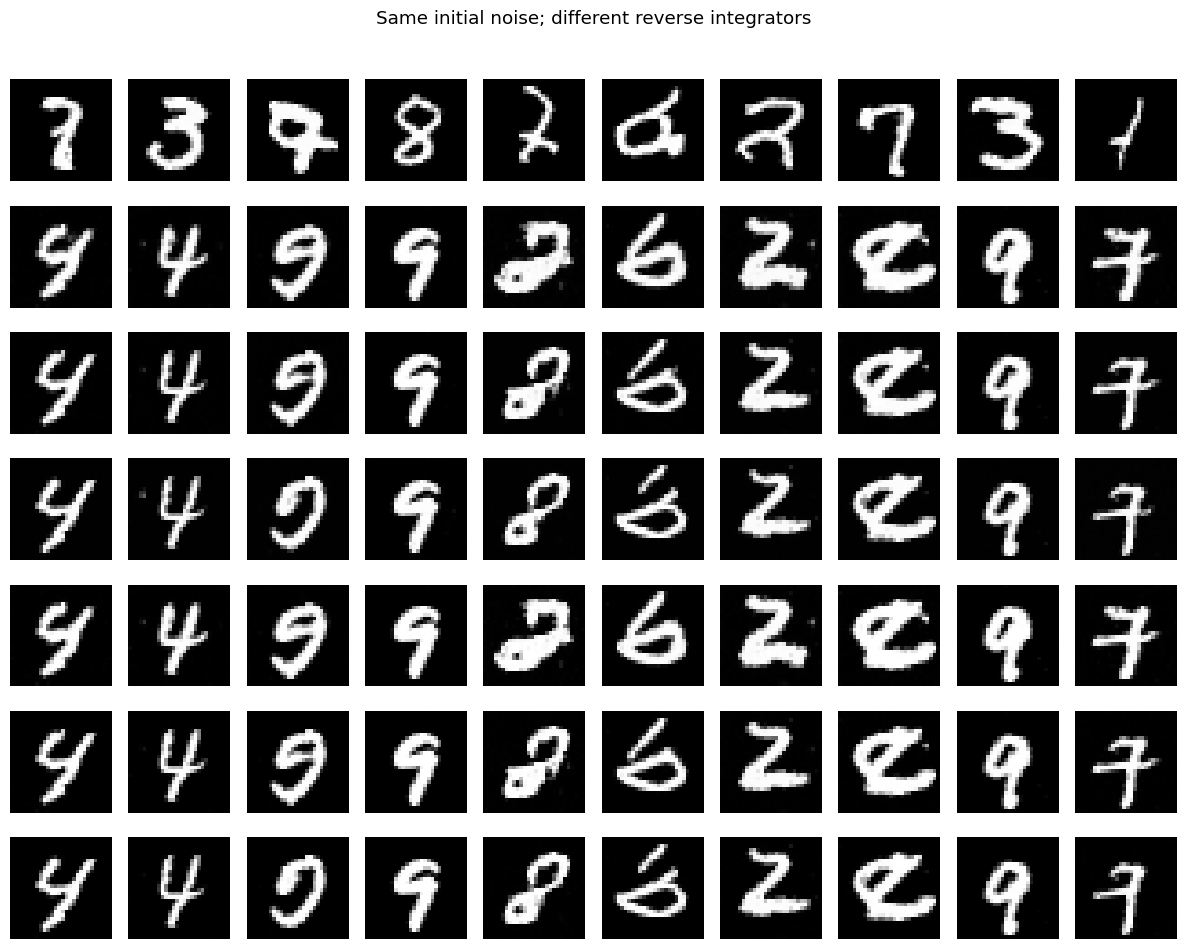

In [8]:
# Warm up kernels before measuring. The result is intentionally discarded.
with torch.no_grad():
    _ = model(
        torch.randn(4, 1, 28, 28, device=DEVICE),
        torch.full((4,), T // 2, device=DEVICE, dtype=torch.long),
    )
synchronize()

SAMPLER_SPECS = [
    {
        "name": "DDPM ancestral",
        "nfe": T,
        "stochastic": True,
        "run": lambda: sample_ddpm(
            model, initial_noise, generator=make_generator(SEED + 100)
        ),
    },
    {
        "name": "DDIM-10",
        "nfe": 10,
        "stochastic": False,
        "run": lambda: sample_ddim(model, initial_noise, n_steps=10, eta=0.0),
    },
    {
        "name": "DDIM-20",
        "nfe": 20,
        "stochastic": False,
        "run": lambda: sample_ddim(model, initial_noise, n_steps=20, eta=0.0),
    },
    {
        "name": "DDIM-50",
        "nfe": 50,
        "stochastic": False,
        "run": lambda: sample_ddim(model, initial_noise, n_steps=50, eta=0.0),
    },
    {
        "name": "DPM++(2M)-10",
        "nfe": 10,
        "stochastic": False,
        "run": lambda: sample_dpmpp_2m(model, initial_noise, n_steps=10),
    },
    {
        "name": "DPM++(2M)-20",
        "nfe": 20,
        "stochastic": False,
        "run": lambda: sample_dpmpp_2m(model, initial_noise, n_steps=20),
    },
    {
        "name": "DPM++(2M)-50",
        "nfe": 50,
        "stochastic": False,
        "run": lambda: sample_dpmpp_2m(model, initial_noise, n_steps=50),
    },
]

results = []
samples_by_name = {}
for specification in SAMPLER_SPECS:
    samples, seconds = timed(specification["run"])
    samples = samples.detach().cpu()
    samples_by_name[specification["name"]] = samples
    results.append(
        {
            "name": specification["name"],
            "nfe": specification["nfe"],
            "stochastic": specification["stochastic"],
            "seconds": seconds,
        }
    )
    print(
        f"{specification['name']:17s} | NFE {specification['nfe']:3d} | "
        f"{seconds:7.3f} s | {1000 * seconds / N_SAMPLES:6.2f} ms/image"
    )

fig, axes = plt.subplots(len(results), 10, figsize=(12, 1.35 * len(results)))
for row, result in enumerate(results):
    images = samples_by_name[result["name"]]
    for column in range(10):
        axes[row, column].imshow(
            images[column, 0].clamp(-1, 1), cmap="gray", vmin=-1, vmax=1
        )
        axes[row, column].axis("off")
    axes[row, 0].set_ylabel(
        result["name"].replace(" ", "\n"), rotation=0, ha="right", va="center"
    )
plt.suptitle("Same initial noise; different reverse integrators", y=1.01)
plt.tight_layout()
plt.show()


>**Expected observation / interpretation.** Skipping steps sharply reduces NFE and usually time. A very aggressive first-order DDIM can lose quality, while the second-order method may use its calls more effectively. Kernel overhead, batching, and synchronization prevent exact proportionality between NFE and seconds.

## 9. A lightweight MNIST quality evaluator

Visual grids are indispensable but subjective. We train or restore a small MNIST classifier and use its hidden representation to calculate three inexpensive diagnostics:

1. **Confidence**: mean maximum class probability. Higher often means more digit-like, but confidence alone can be fooled.
2. **Effective classes**: $\exp(H(p(y)))$. Ten means a balanced class histogram. One indicates complete mode collapse.
3. **Feature Fréchet distance**: distance between Gaussian fits to real and generated classifier features. Lower is better.

This is a convenient analogue of classifier and FID-style evaluation, not a benchmark-grade claim. Only 100 generated samples are used, so reruns will vary. A classifier trained on MNIST may also reward recognizable digits while overlooking other artifacts.


In [9]:
DATA_DIR = NOTEBOOK_DIR / "data/mnist"
DATA_DIR.mkdir(parents=True, exist_ok=True)
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"
FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}
for filename in FILES.values():
    destination = DATA_DIR / filename
    if not destination.exists():
        print(f"Downloading {filename} ...")
        urlretrieve(BASE_URL + filename, destination)


def read_idx_images(path):
    with gzip.open(path, "rb") as file:
        magic, count, rows, columns = struct.unpack(">IIII", file.read(16))
        assert magic == 2051
        array = np.frombuffer(file.read(), dtype=np.uint8).copy()
    images = torch.from_numpy(array.reshape(count, 1, rows, columns)).float() / 255
    return images * 2 - 1


def read_idx_labels(path):
    with gzip.open(path, "rb") as file:
        magic, count = struct.unpack(">II", file.read(8))
        assert magic == 2049
        array = np.frombuffer(file.read(), dtype=np.uint8).copy()
    return torch.from_numpy(array.astype(np.int64))


x_train = read_idx_images(DATA_DIR / FILES["train_images"])
y_train = read_idx_labels(DATA_DIR / FILES["train_labels"])
x_test = read_idx_images(DATA_DIR / FILES["test_images"])
y_test = read_idx_labels(DATA_DIR / FILES["test_labels"])


class MNISTEvaluator(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x, return_features=False):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        features = F.relu(self.fc1(x.flatten(1)))
        if return_features:
            return self.fc2(features), features
        return self.fc2(features)


CLASSIFIER_CHECKPOINT = CHECKPOINT.parent / "mnist_evaluator.pt"
evaluator = MNISTEvaluator().to(DEVICE)
if CLASSIFIER_CHECKPOINT.exists():
    try:
        evaluator.load_state_dict(
            torch.load(CLASSIFIER_CHECKPOINT, map_location=DEVICE, weights_only=True)
        )
    except TypeError:
        evaluator.load_state_dict(torch.load(CLASSIFIER_CHECKPOINT, map_location=DEVICE))
    print(f"Loaded evaluator: {CLASSIFIER_CHECKPOINT}")
else:
    loader = DataLoader(
        TensorDataset(x_train, y_train),
        batch_size=256,
        shuffle=True,
        pin_memory=PIN_MEMORY,
        generator=torch.Generator().manual_seed(SEED),
    )
    optimizer = torch.optim.Adam(evaluator.parameters(), lr=1e-3)
    for epoch in range(1, EVALUATOR_EPOCHS + 1):
        evaluator.train()
        running_loss = 0.0
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            loss = F.cross_entropy(evaluator(images), labels)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(images)
        print(
            f"evaluator epoch {epoch}/{EVALUATOR_EPOCHS} | "
            f"cross entropy {running_loss / len(x_train):.4f}"
        )
    torch.save(evaluator.state_dict(), CLASSIFIER_CHECKPOINT)
    print(f"Saved evaluator: {CLASSIFIER_CHECKPOINT}")

evaluator.eval().requires_grad_(False)
with torch.no_grad():
    correct = 0
    for start in range(0, len(x_test), 512):
        images = x_test[start : start + 512].to(DEVICE)
        labels = y_test[start : start + 512].to(DEVICE)
        correct += (evaluator(images).argmax(1) == labels).sum().item()
print(f"Evaluator test accuracy: {correct / len(x_test):.2%}")


Loaded evaluator: checkpoints/mnist_evaluator.pt
Evaluator test accuracy: 98.73%


In [10]:
@torch.no_grad()
def classifier_outputs(images, batch_size=256):
    probabilities = []
    features = []
    for batch in images.split(batch_size):
        logits, hidden = evaluator(batch.to(DEVICE).clamp(-1, 1), return_features=True)
        probabilities.append(logits.softmax(dim=1).cpu())
        features.append(hidden.cpu())
    return torch.cat(probabilities), torch.cat(features)


def covariance(features):
    centered = features - features.mean(dim=0, keepdim=True)
    return centered.T @ centered / (len(features) - 1)


def feature_frechet_distance(real_features, generated_features):
    """Stable Fréchet distance using a symmetric covariance construction."""
    real = real_features.double()
    generated = generated_features.double()
    mean_term = (real.mean(0) - generated.mean(0)).square().sum()
    covariance_real = covariance(real)
    covariance_generated = covariance(generated)

    eigenvalues, eigenvectors = torch.linalg.eigh(covariance_real)
    covariance_real_sqrt = (
        eigenvectors * eigenvalues.clamp(min=0).sqrt().unsqueeze(0)
    ) @ eigenvectors.T
    middle = covariance_real_sqrt @ covariance_generated @ covariance_real_sqrt
    trace_sqrt = torch.linalg.eigvalsh(middle).clamp(min=0).sqrt().sum()
    distance = (
        mean_term
        + torch.trace(covariance_real)
        + torch.trace(covariance_generated)
        - 2 * trace_sqrt
    )
    return max(0.0, distance.item())


# A fixed real reference makes all sampler comparisons use the same target statistics.
_, reference_features = classifier_outputs(x_test[:2000])

for result in results:
    probabilities, generated_features = classifier_outputs(
        samples_by_name[result["name"]]
    )
    marginal = probabilities.mean(dim=0)
    entropy = -(marginal * marginal.clamp_min(1e-12).log()).sum()
    result["confidence"] = probabilities.max(dim=1).values.mean().item()
    result["effective_classes"] = entropy.exp().item()
    result["coverage"] = int((probabilities.argmax(1).bincount(minlength=10) > 0).sum())
    result["feature_fd"] = feature_frechet_distance(
        reference_features, generated_features
    )

header = (
    f"{'sampler':17s} {'NFE':>4s} {'time(s)':>8s} {'conf.':>7s} "
    f"{'eff.cls':>8s} {'cover':>6s} {'feature-FD':>11s}"
)
print(header)
print("-" * len(header))
for result in results:
    print(
        f"{result['name']:17s} {result['nfe']:4d} {result['seconds']:8.3f} "
        f"{result['confidence']:7.3f} {result['effective_classes']:8.2f} "
        f"{result['coverage']:6d} {result['feature_fd']:11.2f}"
    )


sampler            NFE  time(s)   conf.  eff.cls  cover  feature-FD
-------------------------------------------------------------------
DDPM ancestral     300    0.873   0.931     9.86     10       50.30
DDIM-10             10    0.030   0.900     9.13     10      104.13
DDIM-20             20    0.060   0.903     9.53     10       78.11
DDIM-50             50    0.154   0.918     9.66     10       70.41
DPM++(2M)-10        10    0.048   0.900     9.18     10      102.49
DPM++(2M)-20        20    0.063   0.916     9.55     10       77.00
DPM++(2M)-50        50    0.141   0.913     9.65     10       68.54


## 10. Make stochasticity visible

“Generative models are stochastic” can refer to two separate random sources:

1. **Initial latent noise:** all samplers map different $x_T$ values to different images.
2. **Reverse-path noise conditional on $x_T$:** ancestral DDPM and DDIM with $\eta>0$ can map the *same* $x_T$ to different outputs. Deterministic DDIM and probability-flow ODE solvers cannot.

To isolate the second source, each row below starts eight trajectories from one identical noise tensor. The RMS spread reports pixel-level variation from the first continuation. Zero spread is expected for deterministic methods, up to floating-point effects.

### Predict before running

>**Commit to a prediction:** with the same initial $x_T$, which samplers should return identical repeated outputs, and which should spread? Explain the roles of $x_T$ randomness and reverse-step randomness.

DDPM ancestral      | conditional RMS spread 0.7254 | labels [6, 9, 1, 4, 5, 6, 7, 0]
DDIM-50, eta=0      | conditional RMS spread 0.0000 | labels [4, 4, 4, 4, 4, 4, 4, 4]
DDIM-50, eta=0.5    | conditional RMS spread 0.6267 | labels [2, 4, 8, 2, 7, 5, 7, 2]
DDIM-50, eta=1      | conditional RMS spread 0.6995 | labels [7, 1, 2, 6, 9, 4, 0, 3]
DPM++(2M)-20        | conditional RMS spread 0.0001 | labels [4, 4, 4, 4, 4, 4, 4, 4]


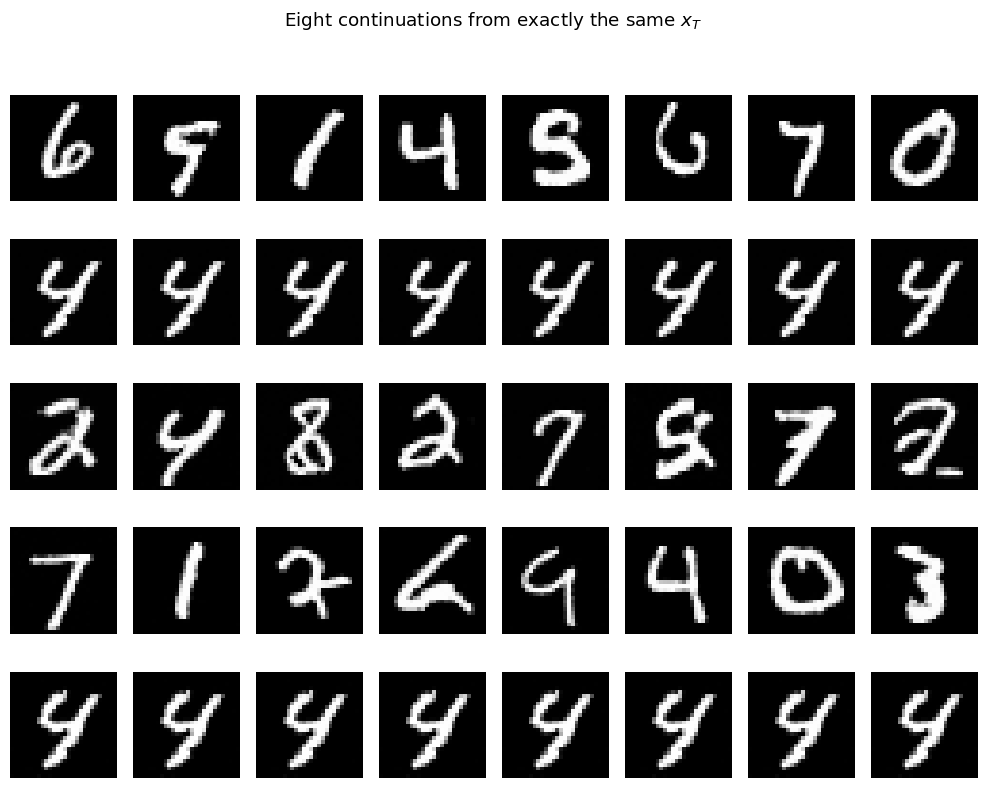

In [11]:
shared_noise = initial_noise[:1].expand(8, -1, -1, -1).clone()
branch_specs = [
    (
        "DDPM ancestral",
        lambda: sample_ddpm(model, shared_noise, generator=make_generator(SEED + 901)),
    ),
    (
        "DDIM-50, eta=0",
        lambda: sample_ddim(model, shared_noise, 50, eta=0.0),
    ),
    (
        "DDIM-50, eta=0.5",
        lambda: sample_ddim(
            model, shared_noise, 50, eta=0.5, generator=make_generator(SEED + 902)
        ),
    ),
    (
        "DDIM-50, eta=1",
        lambda: sample_ddim(
            model, shared_noise, 50, eta=1.0, generator=make_generator(SEED + 903)
        ),
    ),
    (
        "DPM++(2M)-20",
        lambda: sample_dpmpp_2m(model, shared_noise, 20),
    ),
]

branch_outputs = {}
for name, run in branch_specs:
    output = run().detach().cpu()
    branch_outputs[name] = output
    rms_spread = torch.sqrt(
        (output[1:] - output[:1]).square().flatten(1).mean(dim=1)
    ).mean()
    labels = evaluator(output.to(DEVICE).clamp(-1, 1)).argmax(1).cpu().tolist()
    print(f"{name:19s} | conditional RMS spread {rms_spread:.4f} | labels {labels}")

fig, axes = plt.subplots(len(branch_specs), 8, figsize=(10, 1.6 * len(branch_specs)))
for row, (name, _) in enumerate(branch_specs):
    for column, image in enumerate(branch_outputs[name]):
        axes[row, column].imshow(image[0].clamp(-1, 1), cmap="gray", vmin=-1, vmax=1)
        axes[row, column].axis("off")
    axes[row, 0].set_ylabel(name.replace(", ", "\n"), rotation=0, ha="right", va="center")
plt.suptitle("Eight continuations from exactly the same $x_T$", y=1.01)
plt.tight_layout()
plt.show()


>**Expected observation / interpretation.** Deterministic samplers map a fixed $x_T$ to one fixed output. Stochastic DDPM or DDIM with $\eta>0$ produces a conditional spread. Deterministic sampling remains generative because different initial noise still gives different outputs.

## 11. The speed-quality trade-off

No single scalar determines the winner. The following plots put the feature distance against both NFE and measured time. The desirable region is the lower left. An efficient higher-order solver should reach a given quality with fewer evaluations than a first-order method, although model error, clipping, and the coarse training grid can change the ranking.


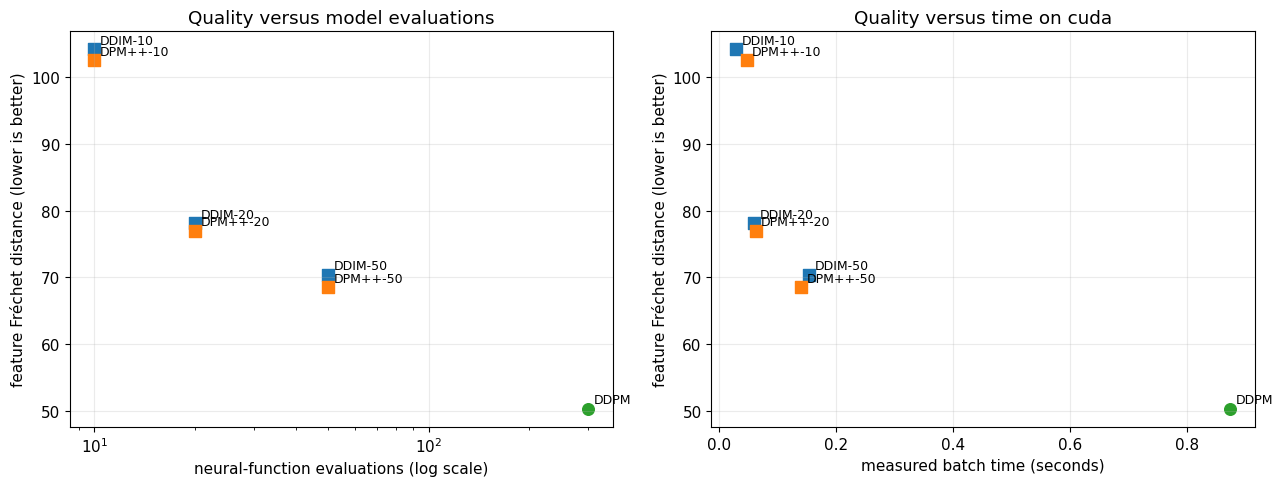

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for result in results:
    marker = "o" if result["stochastic"] else "s"
    color = (
        "tab:blue"
        if result["name"].startswith("DDIM")
        else "tab:orange"
        if result["name"].startswith("DPM")
        else "tab:green"
    )
    axes[0].scatter(result["nfe"], result["feature_fd"], marker=marker, color=color, s=70)
    axes[1].scatter(result["seconds"], result["feature_fd"], marker=marker, color=color, s=70)
    short_name = result["name"].replace(" ancestral", "").replace("DPM++(2M)", "DPM++")
    axes[0].annotate(short_name, (result["nfe"], result["feature_fd"]), xytext=(4, 4), textcoords="offset points", fontsize=9)
    axes[1].annotate(short_name, (result["seconds"], result["feature_fd"]), xytext=(4, 4), textcoords="offset points", fontsize=9)

axes[0].set_xscale("log")
axes[0].set(xlabel="neural-function evaluations (log scale)", ylabel="feature Fréchet distance (lower is better)", title="Quality versus model evaluations")
axes[1].set(xlabel="measured batch time (seconds)", ylabel="feature Fréchet distance (lower is better)", title=f"Quality versus time on {DEVICE.type}")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 12. Interpreting the trade-offs

| Sampler | Typical NFE here | Reverse path | Main strength | Main limitation |
|---|---:|---|---|---|
| Ancestral DDPM | 300 | Stochastic | Faithfully follows the trained adjacent reverse chain | Slow. Randomness is injected at every step |
| DDIM, $\eta=0$ | 10-50 | Deterministic given $x_T$ | Simple, fast, and supports latent interpolation/inversion ideas | First-order error becomes visible with very few steps |
| DDIM, $\eta>0$ | 10-50 | Stochastic | Continuously adjustable diversity conditional on $x_T$ | More randomness does not automatically improve quality |
| DPM-Solver++(2M) | 10-50 | Deterministic here | Higher-order accuracy per expensive model call | More algorithmic assumptions and implementation complexity |

### What to look for in the output

- **Speed:** NFE should track time approximately, but GPU launch overhead and batch size matter. A 15× NFE reduction need not be exactly a 15× wall-clock reduction.
- **Quality:** very small step counts can distort strokes or lose class coverage. The second-order method often improves the low-NFE regime, but verify rather than assume this.
- **Stochasticity:** deterministic does not mean non-generative—randomness still enters through $x_T$. It means there is one output for each fixed initial latent.
- **Coverage:** sharp samples are not enough if only a subset of digits appears. Read confidence together with effective classes and the visual grid.
- **Fairness:** changing the denoiser, schedule, initial-noise batch, or evaluator would confound the sampler comparison.


## Takeaways and homework experiments 

### Takeaways

Training learns a time-dependent vector field. Sampling decides how to integrate it. Ancestral DDPM spends many stochastic steps to stay close to the learned reverse chain, DDIM trades integration accuracy for large speedups and exposes a randomness knob, and modern diffusion ODE solvers use higher-order structure to reduce the speed-quality trade-off. The best sampler depends on whether the application values latency, fidelity, reproducibility, or multiple plausible continuations from the same latent state.

### Mini-experiment 1 — Resolve the NFE frontier
- **Hypothesis:** Quality improves with NFE but with diminishing returns. The second-order solver should be strongest in part of the low-NFE regime.
- **Metric/plot:** Plot feature distance, confidence, effective classes, and wall-clock time for `[5, 10, 20, 30, 50, 100]` steps.
- **Controls:** Fix checkpoint, initial-noise batch, evaluator, device, warm-up, and sample count.
- **Interpretation:** Identify Pareto-efficient points rather than selecting by one metric. 

### Mini-experiment 2 — DDIM stochasticity sweep
- **Hypothesis:** Increasing $\eta$ raises conditional spread from fixed $x_T$, but does not monotonically improve feature distance.
- **Metric/plot:** Plot conditional RMS spread and feature distance versus $\eta$, with matched sample grids.
- **Controls:** Hold checkpoint, state schedule, step count, initial $x_T$, and random-seed set fixed.
- **Interpretation:** Separate diversity conditional on one latent from diversity across different initial latents. 

### Extensions
- Compare uniform state spacing with spacing uniform in log-SNR $\lambda$.
- Remove $\hat x_0$ clipping and inspect numerical instability near $x_T$.
- Replace the midpoint DPM-Solver++ correction with its Heun coefficient.
- Implement an adaptive probability-flow ODE solver and count rejected as well as accepted NFE.
- Scale evaluation to thousands of samples and bootstrap confidence intervals.


## Exit ticket

1. Why is NFE useful but insufficient for comparing sampler speed?
<details><summary>Self-check</summary>NFE counts expensive model calls, but overhead, batching, hardware, and synchronization also affect wall-clock time.</details>

2. Why is deterministic DDIM still a generative sampler?
<details><summary>Self-check</summary>It is deterministic only conditional on $x_T$. Drawing different initial Gaussian noise still produces different samples.</details>

3. What are three controls required for a fair speed–quality comparison?
<details><summary>Self-check</summary>Examples: same checkpoint/schedule, initial-noise batch, sample count, evaluator, device, and timing warm-up.</details>

## References and further reading

- [Song, Meng & Ermon, “Denoising Diffusion Implicit Models” (ICLR 2021)](https://openreview.net/forum?id=St1giarCHLP): Derives the step-skipping family and the $\eta$ stochasticity control.
- [Lu et al., “DPM-Solver” (NeurIPS 2022)](https://proceedings.neurips.cc/paper_files/paper/2022/hash/260a14acce2a89dad36adc8eefe7c59e-Abstract-Conference.html): Develops diffusion-specific high-order solvers that motivate the low-NFE comparison.
- [Hugging Face Diffusers scheduler documentation](https://huggingface.co/docs/diffusers/api/schedulers/overview): Accessible guidance on how production libraries separate a trained denoiser from sampler/scheduler choices.